# Etapa 2 — otimização de dieta de menor custo

Nesta etapa, as quantidades dos ingredientes deixam de ser percentuais fixos e passam a ser variáveis de decisão. O formulador interno do RuFaS procura a dieta diária de menor custo que atenda às restrições nutricionais NASEM para as vacas em lactação.

## 1. Formulação matemática

Para cada ingrediente $i$, a variável $x_i$ representa **kg de matéria seca por vaca por dia**. O preço $p_i$ é informado em **USD por kg de matéria seca**.

$$\min C(x) = \sum_i p_i x_i$$

O RuFaS resolve o problema com **SLSQP**, impondo restrições de energia líquida, proteína, cálcio, fósforo, fibra em detergente neutro (NDF), NDF de forragem, gordura e consumo de matéria seca. Portanto, esta etapa é uma otimização nutricional de menor custo, não apenas uma comparação manual.

In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from rufas_project import (
    DietConfig, DietIngredient, EconomicConfig, HerdConfig, MilkConfig,
    ParityFractions, SimulationConfig, build_min_cost_scenario,
    calculate_economics, compare_scenarios, describe_min_cost_problem,
    load_result, submit_simulation, summarize_lactating_ration,
    validate_simulation_config, wait_for_simulation,
)

SHARED_ROOT = Path(os.getenv('SHARED_ROOT', '/workspace/shared'))
TABLE_STYLES = [
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px 0')]},
    {'selector': 'th', 'props': [('background-color', '#256a4b'), ('color', 'white'), ('padding', '8px')]},
    {'selector': 'td', 'props': [('padding', '7px 12px'), ('border-bottom', '1px solid #e5e7eb')]},
]

def show_table(frame, caption, hide_index=True, formatter=None):
    styled = frame.style.set_caption(caption).set_table_styles(TABLE_STYLES)
    if hide_index:
        styled = styled.hide(axis='index')
    if formatter:
        styled = styled.format(formatter)
    display(styled)

## 2. Entradas do cenário de referência

Todos os valores continuam visíveis no notebook. Os preços abaixo vêm do exemplo oficial do RuFaS e são didáticos; uma aplicação real precisa substituí-los por preços regionais, datados e documentados.

In [3]:
reference = SimulationConfig(
    name='fase2_dieta_referencia',
    simulation_days=30,
    random_seed=42,
    herd=HerdConfig(
        cow_num=20, milking_cow_fraction=0.80, breed='HO',
        parity_fractions=ParityFractions(0.40, 0.25, 0.20, 0.10, 0.05),
    ),
    milk=MilkConfig(fat_percent=4.0, protein_percent=3.2, mature_body_weight_kg=740.1),
    diet=DietConfig(
        mode='fixed', formulation_interval_days=30,
        ingredients=[
            DietIngredient(23, 0.74, 0.10, 'Blood meal, low dRUP'),
            DietIngredient(44, 15.31, 0.50, 'Corn grain dry, medium grind'),
            DietIngredient(50, 37.45, 0.01, 'Corn silage, immature'),
            DietIngredient(104, 0.37, 0.01, 'Grass/legume mix, legume silage'),
            DietIngredient(110, 17.65, 0.01, 'Legume silage, mid-maturity'),
            DietIngredient(301, 3.27, 1.00, 'Farm ES Mineral Mix'),
            DietIngredient(302, 25.21, 0.10, 'Farm ES Midwest BP Blend'),
        ],
    ),
    economics=EconomicConfig(
        milk_price_usd_per_kg=0.45,
        milk_price_source='Hipótese didática; substituir por fonte, região e data',
        currency='USD',
    ),
)

names_pt = {
    23: 'Farinha de sangue, baixo teor de dRUP',
    44: 'Grão de milho seco, moagem média',
    50: 'Silagem de milho imatura',
    104: 'Mistura de gramínea e leguminosa ensilada',
    110: 'Silagem de leguminosa em maturação intermediária',
    301: 'Mistura mineral da fazenda (ES)',
    302: 'Mistura de subprodutos do Meio-Oeste (BP)',
}
ingredients_table = pd.DataFrame([
    {
        'ID no RuFaS': item.feed_type,
        'Ingrediente candidato': names_pt[item.feed_type],
        'Dieta de referência': item.ration_percentage,
        'Preço (USD/kg MS)': item.purchased_feed_cost_usd_per_kg_dm,
    }
    for item in reference.diet.ingredients
])
show_table(
    ingredients_table, 'Ingredientes e preços informados ao otimizador',
    formatter={'Dieta de referência': '{:.2f}%', 'Preço (USD/kg MS)': '{:.2f}'},
)

ID no RuFaS,Ingrediente candidato,Dieta de referência,Preço (USD/kg MS)
23,"Farinha de sangue, baixo teor de dRUP",0.74%,0.10
44,"Grão de milho seco, moagem média",15.31%,0.50
50,Silagem de milho imatura,37.45%,0.01
104,Mistura de gramínea e leguminosa ensilada,0.37%,0.01
110,Silagem de leguminosa em maturação intermediária,17.65%,0.01
301,Mistura mineral da fazenda (ES),3.27%,1.00
302,Mistura de subprodutos do Meio-Oeste (BP),25.21%,0.10


## 3. Definição formal do problema

In [4]:
optimized = build_min_cost_scenario(reference, name='fase2_dieta_otimizada')
show_table(describe_min_cost_problem(optimized), 'Problema de otimização executado pelo RuFaS')

Elemento,Definição
Variáveis de decisão,xᵢ = kg de matéria seca do ingrediente i por vaca e por dia
Função objetivo,min C(x) = Σ pᵢ × xᵢ
Preço,pᵢ = USD por kg de matéria seca do ingrediente i
Método numérico,"SLSQP, executado pelo formulador interno do RuFaS"
Padrão nutricional,NASEM
Restrições,"Energia líquida, proteína, cálcio, fósforo, NDF, NDF de forragem, gordura e consumo de matéria seca"
Ingredientes candidatos,7 ingredientes informados no notebook
Critério de comparação,"Custo alimentar, produção de leite, receita e margem sobre alimentação"


## 4. Validação antes da execução

In [5]:
validate_simulation_config(reference)
validate_simulation_config(optimized)
validation_table = pd.DataFrame([
    ('Referência', 'Percentuais fixos', 'Válida'),
    ('Otimizada', 'Menor custo com restrições NASEM', 'Válida'),
], columns=['Cenário', 'Método de formulação', 'Validação'])
show_table(validation_table, 'Cenários prontos para execução')

Cenário,Método de formulação,Validação
Referência,Percentuais fixos,Válida
Otimizada,Menor custo com restrições NASEM,Válida


## 5. Execução da dieta de referência e da otimização

Os dois cenários usam o mesmo rebanho, período, semente, ingredientes e preços. A única diferença é o método de formulação da dieta.

In [6]:
reference_job = submit_simulation(reference, SHARED_ROOT)
wait_for_simulation(reference_job, SHARED_ROOT, timeout_seconds=1800)
reference_result = load_result(reference_job, SHARED_ROOT)
print('Dieta de referência concluída.')

Aguardando: Solicitação gravada; aguardando o worker do RuFaS
Em execução: Executando o main.py do RuFaS
Concluída: Simulação concluída e resultados processados
Dieta de referência concluída.


In [7]:
optimized_job = submit_simulation(optimized, SHARED_ROOT)
wait_for_simulation(optimized_job, SHARED_ROOT, timeout_seconds=1800)
optimized_result = load_result(optimized_job, SHARED_ROOT)
execution_table = pd.DataFrame([
    ('Referência', reference_job, 'Concluída'),
    ('Otimizada', optimized_job, 'Concluída'),
], columns=['Cenário', 'Identificador', 'Situação'])
show_table(execution_table, 'Execuções utilizadas na comparação')

Aguardando: Solicitação gravada; aguardando o worker do RuFaS
Em execução: Executando o main.py do RuFaS
Concluída: Simulação concluída e resultados processados


Cenário,Identificador,Situação
Referência,63405467-c26c-4b3a-aea9-7049189c9f47,Concluída
Otimizada,e9faf06f-14b8-4d93-92bf-84ebb9c7d2e6,Concluída


## 6. Dieta encontrada

As quantidades abaixo são médias diárias por vaca em lactação. Ingredientes com quantidade zero são omitidos da dieta otimizada.

In [8]:
reference_ration, reference_totals = summarize_lactating_ration(reference_result, reference)
optimized_ration, optimized_totals = summarize_lactating_ration(optimized_result, optimized)
composition = (
    reference_ration[['feed_type', 'average_kg_dm_per_cow_day', 'percentage_dm']]
    .merge(
        optimized_ration[['feed_type', 'average_kg_dm_per_cow_day', 'percentage_dm']],
        on='feed_type', how='outer', suffixes=('_reference', '_optimized'),
    )
    .fillna(0)
)
composition['Ingrediente'] = composition['feed_type'].map(names_pt)
composition_display = composition.rename(columns={
    'feed_type': 'ID',
    'average_kg_dm_per_cow_day_reference': 'Referência (kg MS/vaca/dia)',
    'percentage_dm_reference': 'Referência (%)',
    'average_kg_dm_per_cow_day_optimized': 'Otimizada (kg MS/vaca/dia)',
    'percentage_dm_optimized': 'Otimizada (%)',
})[[
    'ID', 'Ingrediente', 'Referência (kg MS/vaca/dia)', 'Referência (%)',
    'Otimizada (kg MS/vaca/dia)', 'Otimizada (%)',
]]
show_table(
    composition_display, 'Composição média das dietas',
    formatter={
        'Referência (kg MS/vaca/dia)': '{:.3f}', 'Referência (%)': '{:.2f}%',
        'Otimizada (kg MS/vaca/dia)': '{:.3f}', 'Otimizada (%)': '{:.2f}%',
    },
)

ID,Ingrediente,Referência (kg MS/vaca/dia),Referência (%),Otimizada (kg MS/vaca/dia),Otimizada (%)
23,"Farinha de sangue, baixo teor de dRUP",0.217,0.78%,0.616,1.96%
44,"Grão de milho seco, moagem média",3.666,13.25%,0.000,0.00%
50,Silagem de milho imatura,10.962,39.61%,7.090,22.55%
104,Mistura de gramínea e leguminosa ensilada,0.108,0.39%,10.585,33.66%
110,Silagem de leguminosa em maturação intermediária,5.166,18.67%,13.155,41.83%
301,Mistura mineral da fazenda (ES),0.783,2.83%,0.000,0.00%
302,Mistura de subprodutos do Meio-Oeste (BP),6.773,24.47%,0.000,0.00%


## 7. Comparação produtiva e econômica

In [9]:
reference_economics = calculate_economics(reference_result, reference)
optimized_economics = calculate_economics(optimized_result, optimized)
comparison = compare_scenarios({
    'Dieta de referência': (reference_result, reference_economics),
    'Dieta otimizada': (optimized_result, optimized_economics),
}).rename(columns={
    'milk_kg': 'Leite total (kg)',
    'average_daily_milk_kg': 'Leite médio (kg/dia)',
    'feed_cost': 'Custo alimentar (USD)',
    'milk_revenue': 'Receita do leite (USD)',
    'margin_over_feed_cost': 'Margem alimentar (USD)',
}).rename_axis('Cenário')
show_table(comparison, 'Resultados dos cenários', hide_index=False, formatter='{:,.2f}')

ration_comparison = pd.DataFrame([
    ('Consumo de matéria seca', reference_totals['average_kg_dm_per_cow_day'], optimized_totals['average_kg_dm_per_cow_day'], 'kg MS/vaca/dia'),
    ('Custo médio da dieta', reference_totals['average_cost_usd_per_cow_day'], optimized_totals['average_cost_usd_per_cow_day'], 'USD/vaca/dia'),
], columns=['Indicador', 'Referência', 'Otimizada', 'Unidade'])
ration_comparison['Variação (%)'] = (ration_comparison['Otimizada'] / ration_comparison['Referência'] - 1) * 100
show_table(
    ration_comparison, 'Efeito da otimização sobre a dieta',
    formatter={'Referência': '{:,.3f}', 'Otimizada': '{:,.3f}', 'Variação (%)': '{:+.2f}%'},
)

,Leite total (kg),Leite médio (kg/dia),Custo alimentar (USD),Receita do leite (USD),Margem alimentar (USD)
Cenário,,,,,
Dieta de referência,"22,442.17",748.07,"1,950.97","10,098.98","8,148.01"
Dieta otimizada,"22,442.17",748.07,207.53,"10,098.98","9,891.44"


Indicador,Referência,Otimizada,Unidade,Variação (%)
Consumo de matéria seca,27.675,31.447,kg MS/vaca/dia,+13.63%
Custo médio da dieta,3.478,0.370,USD/vaca/dia,-89.36%


## 8. Visualização da solução

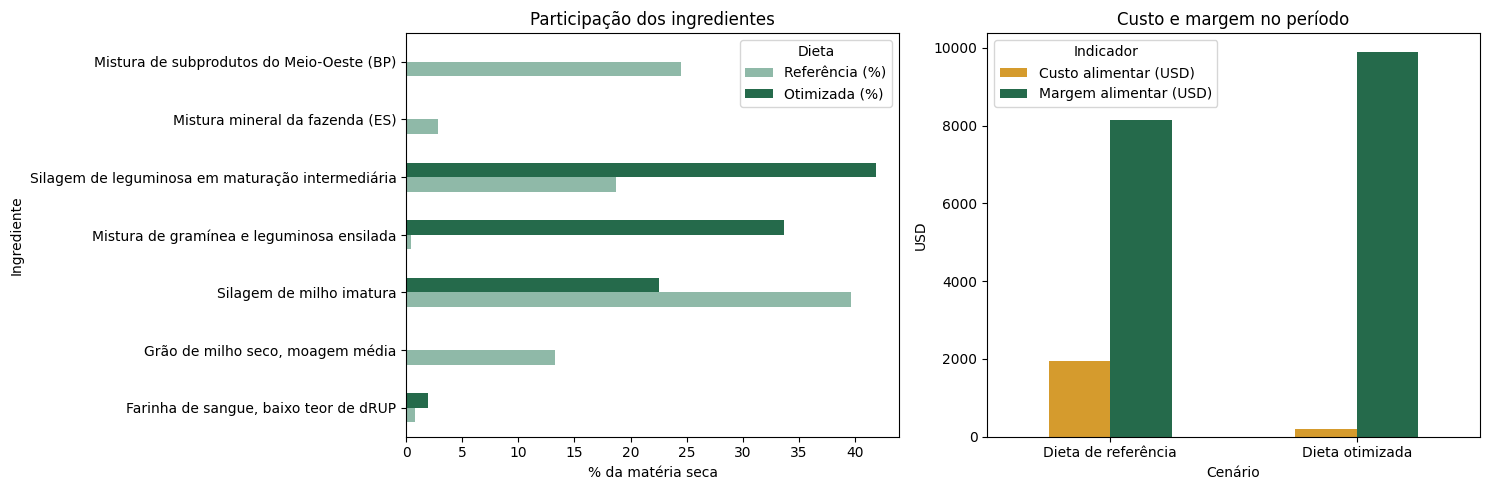

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
composition_display.set_index('Ingrediente')[[
    'Referência (%)', 'Otimizada (%)'
]].plot.barh(ax=axes[0], color=['#8fb9a8', '#256a4b'])
axes[0].set_title('Participação dos ingredientes')
axes[0].set_xlabel('% da matéria seca')
axes[0].set_ylabel('Ingrediente')
axes[0].legend(title='Dieta')

comparison[['Custo alimentar (USD)', 'Margem alimentar (USD)']].plot.bar(
    ax=axes[1], color=['#d59b2d', '#256a4b']
)
axes[1].set_title('Custo e margem no período')
axes[1].set_xlabel('Cenário')
axes[1].set_ylabel('USD')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Indicador')
plt.tight_layout()

## 9. Interpretação e limites

A dieta otimizada é a solução de menor custo **para os ingredientes, preços, animais e restrições informados**. Ela não deve ser aplicada diretamente em uma fazenda sem revisão de um nutricionista. Os preços do exemplo são didáticos, e esta análise econômica considera somente receita do leite menos alimentação das vacas em lactação.

A Etapa 3 está implementada em `03_analise_sensibilidade.ipynb`. Ela repete a otimização com variações sistemáticas de preço para medir a sensibilidade da composição, do custo e da margem.